# Momentum: quick look

Backtest and walk-forward of `TopNMomentum` on the strategy framework (`analysis/framework`).
Orders execute at the next open with 5 + 5 bps costs by default; cash earns the Fama-French risk-free rate.

In [1]:
import os
import sys

# run from the repo root: the etl models resolve ./dataplatform relative to it
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("../..")
sys.path.append(os.getcwd())

import polars as pl

from etl.transformation.gold import StocksMlReadyGold
from analysis.framework import BacktestConfig, load_risk_free, run_backtest
from analysis.framework.plotting import plot_result
from analysis.strategies.momentum import TopNMomentum, adaptive_momentum

In [2]:
df = (
    StocksMlReadyGold()
    .read_from_disk()
    .select("timeframe", "symbol", "open", "high", "low", "close")
    .collect()
)
rf = load_risk_free()
df["timeframe"].min(), df["timeframe"].max(), df["symbol"].n_unique()

[01:20:31] gold.stocks_ml_ready is of VIEW kind and cannot be read from disk, defaulting to .build() call
[01:20:31] Building from source data model gold.stocks_ml_ready
[01:20:31] gold.stocks_daily is of VIEW kind and cannot be read from disk, defaulting to .build() call
[01:20:31] Building from source data model gold.stocks_daily
[01:20:31] gold.stocks_daily build plan ready and validated
[01:20:31] gold.stocks_ml_ready build plan ready and validated


/tmp/ipykernel_130412/2804843724.py:5: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  .collect()


(datetime.date(2021, 1, 4), datetime.date(2026, 7, 30), 4093)

## Fixed parameters

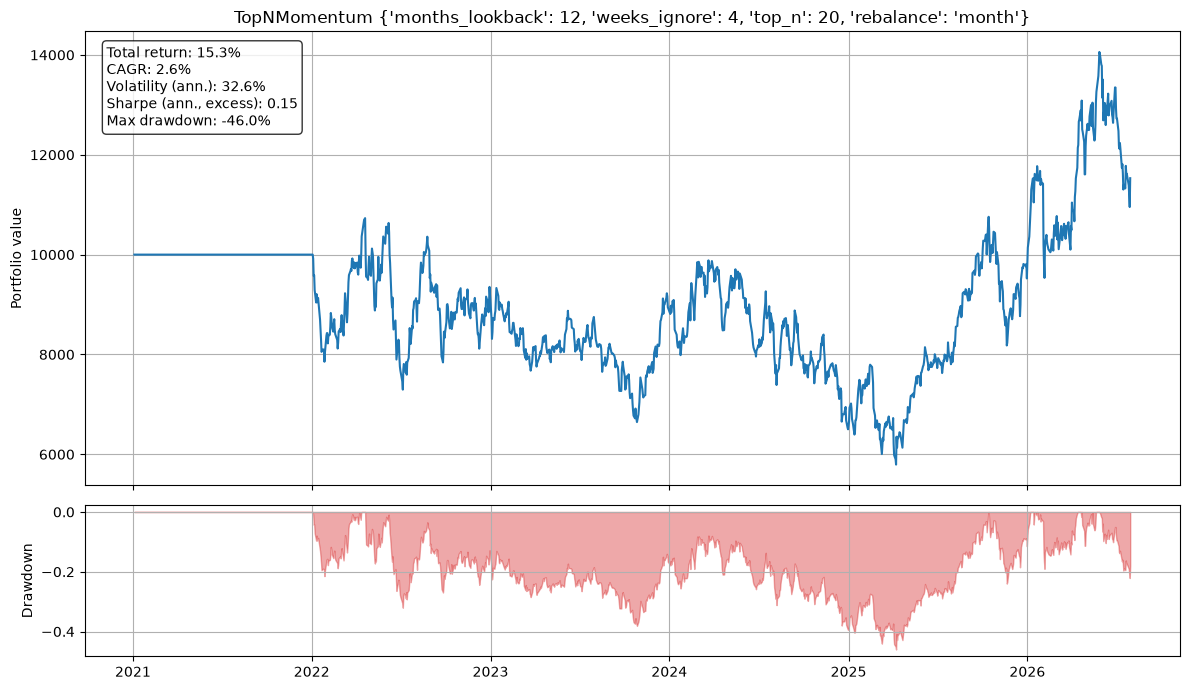

kind,len
str,u32
"""buys_scaled""",52
"""exit_deferred""",21
"""buy_skipped""",7
"""delisting""",38
"""rebalance_skipped""",16


In [3]:
result = run_backtest(
    TopNMomentum(months_lookback=12, weeks_ignore=4, top_n=20, rebalance="month"),
    df,
    BacktestConfig(),
    risk_free=rf,
)
plot_result(result)
result.events.group_by("kind").len()

## Adaptive: parameters re-optimized every quarter

Walk-forward over the grid of the old `AdaptiveTopNReturnsMomentum` (54 candidates): each quarter, the best parameters by trailing-year Sharpe trade the next quarter.

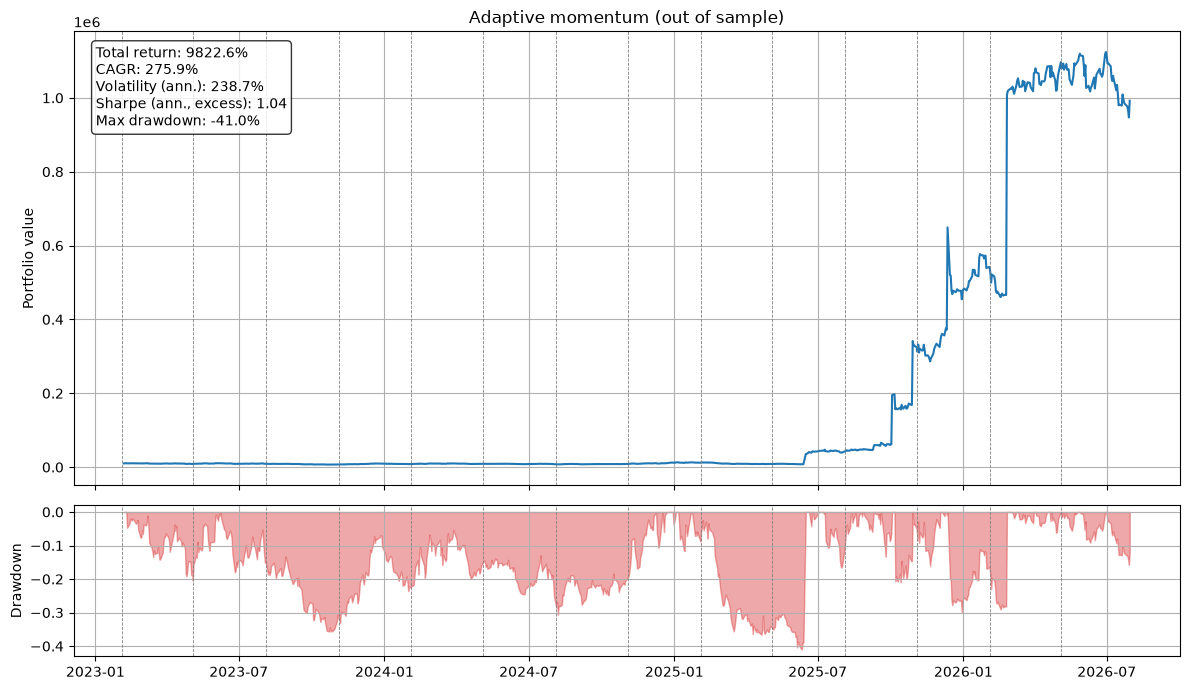

{'total_return': 98.22642089877141,
 'cagr': 2.758622161137193,
 'volatility': 2.3868812800759747,
 'sharpe': 1.0410275971680967,
 'max_drawdown': -0.41006434570291384,
 'oos_score': 1.0410275971680967,
 'mean_train_score': 1.2530434965992303,
 'mean_test_score': 0.39194784664433335,
 'is_oos_gap': 0.861095649954897}

In [4]:
wf = adaptive_momentum(df, reoptimize="3mo", risk_free=rf, n_jobs=6)
plot_result(wf.oos, title="Adaptive momentum (out of sample)", fold_starts=wf.folds["test_start"])
wf.metrics

In [5]:
wf.folds.unnest("params")

fold,train_start,train_end,test_start,test_end,months_lookback,weeks_ignore,top_n,rebalance,train_score,test_score
i64,date,date,date,date,i64,i64,i64,str,f64,f64
0,2022-02-04,2023-02-04,2023-02-04,2023-05-04,3,2,10,"""week""",0.691509,-1.279174
1,2022-05-04,2023-05-04,2023-05-04,2023-08-04,9,4,10,"""quarter""",1.238766,0.370173
2,2022-08-04,2023-08-04,2023-08-04,2023-11-04,9,2,10,"""month""",1.091432,-2.384024
3,2022-11-04,2023-11-04,2023-11-04,2024-02-04,12,4,10,"""week""",0.24722,1.291993
4,2023-02-04,2024-02-04,2024-02-04,2024-05-04,9,2,30,"""quarter""",0.975705,0.871539
…,…,…,…,…,…,…,…,…,…,…
9,2024-05-04,2025-05-04,2025-05-04,2025-08-04,3,2,20,"""week""",1.090736,2.047682
10,2024-08-04,2025-08-04,2025-08-04,2025-11-04,3,2,30,"""week""",1.28399,2.871263
11,2024-11-04,2025-11-04,2025-11-04,2026-02-04,3,4,30,"""week""",1.941631,1.864738
